In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
roc_curve,
auc)

In [4]:
data=load_breast_cancer()
x=data.data
y=data.target
np.unique(y)

array([0, 1])

In [5]:
x_train,x_test,y_train,y_test=train_test_split(x,
y,
test_size=0.2,
random_state=42,
stratify=y)

In [6]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)
mle_model=LogisticRegression(
    penalty=None,
    max_iter=5000,
    random_state=42
)
mle_model.fit(x_train,y_train)
y_pred_mle=mle_model.predict(x_test)

In [7]:
map_l2=LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=5000,
    random_state=42)
map_l2.fit(x_train,y_train)
y_pred_l2=map_l2.predict(x_test)

In [8]:
map_l1=LogisticRegression(
    penalty='l1',
    C=1.0,
    solver='liblinear',
    max_iter=5000,
    random_state=42)
map_l1.fit(x_train,y_train)
y_pred_l1=map_l1.predict(x_test)

In [9]:
def evaluate(model_name,y_true,y_pred):
    print("\n","="*40)
    print(model_name)
    print("="*40)
    print("accuracy:",accuracy_score(y_true,y_pred))
    print("precision:",precision_score(y_true,y_pred))
    print("recall:",recall_score(y_true,y_pred))
    print("f1-score:",f1_score(y_true,y_pred))
    print("\nConfusion Matrix")
    print(confusion_matrix(y_true,y_pred))
    

In [10]:
evaluate("MLE",y_test,y_pred_mle)
evaluate("MAP(L2)",y_test,y_pred_l2)
evaluate("MAP(L1)",y_test,y_pred_l1)


MLE
accuracy: 0.9210526315789473
precision: 0.9701492537313433
recall: 0.9027777777777778
f1-score: 0.935251798561151

Confusion Matrix
[[40  2]
 [ 7 65]]

MAP(L2)
accuracy: 0.9824561403508771
precision: 0.9861111111111112
recall: 0.9861111111111112
f1-score: 0.9861111111111112

Confusion Matrix
[[41  1]
 [ 1 71]]

MAP(L1)
accuracy: 0.9912280701754386
precision: 0.9863013698630136
recall: 1.0
f1-score: 0.993103448275862

Confusion Matrix
[[41  1]
 [ 0 72]]


In [11]:
print("number of zero coefficient")
print("mle:",np.sum(mle_model.coef_[0]==0))
print("mapl2:",np.sum(map_l2.coef_[0]==0))
print("mapl1:",np.sum(map_l1.coef_[0]==0))



number of zero coefficient
mle: 0
mapl2: 0
mapl1: 14


In [12]:
results=pd.DataFrame(columns=[
    "model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"])
models=[
    ("MLE",mle_model,
     y_pred_mle),
    ("MAP_L2",map_l2,y_pred_l2),
    ("MAP_L1",map_l1,y_pred_l1)]

In [13]:
for name,model,pred in models:
    results.loc[len(results)]=[
    name,
    accuracy_score(y_test,pred),
    precision_score(y_test,pred),
    recall_score(y_test,pred),
    f1_score(y_test,pred)]
print(results)

    model  Accuracy  Precision    Recall  F1-score
0     MLE  0.921053   0.970149  0.902778  0.935252
1  MAP_L2  0.982456   0.986111  0.986111  0.986111
2  MAP_L1  0.991228   0.986301  1.000000  0.993103


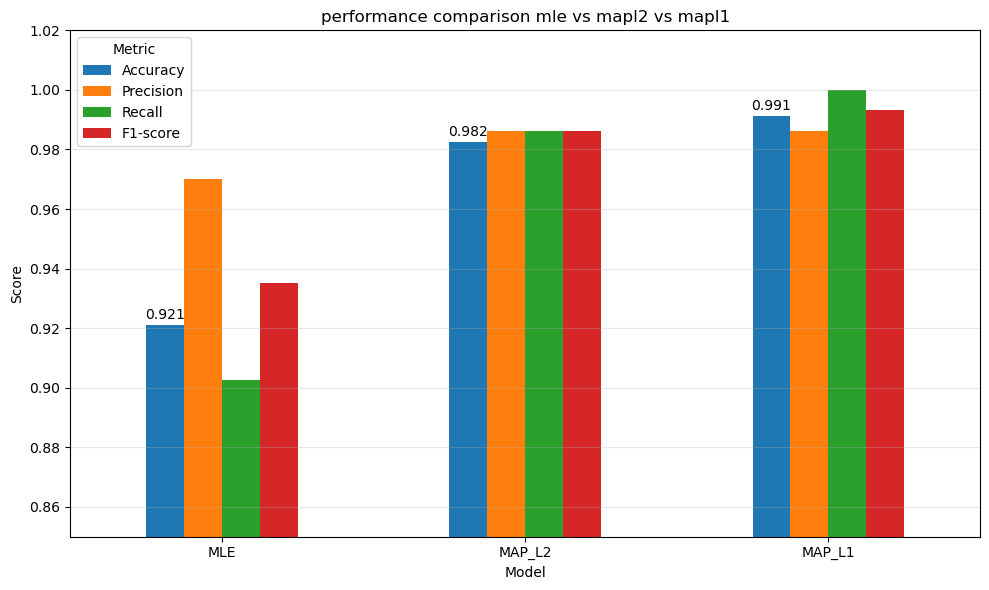

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [18]:
ax=results.set_index("model").plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("performance comparison mle vs mapl2 vs mapl1")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.85,1.02)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y",alpha=0.3)
for container in ax.containers:
    ax.bar_label(container,fmt="%.3f",padding=2)
    plt.tight_layout()
    plt.show()

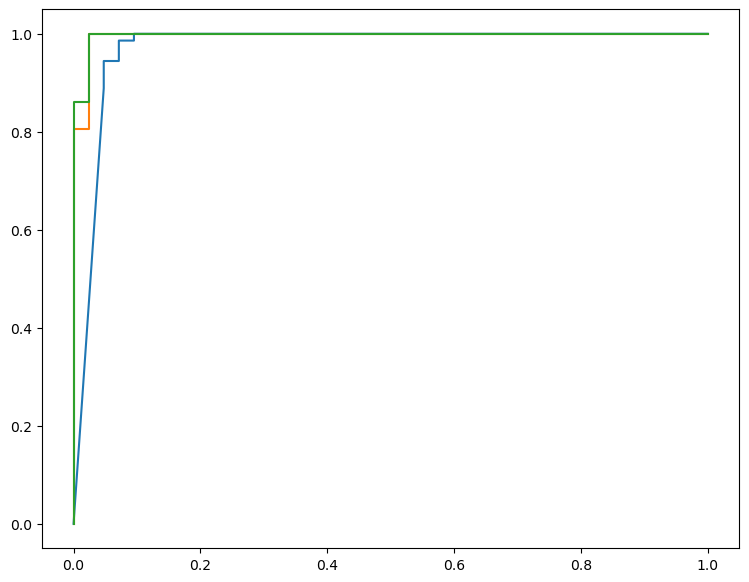

In [40]:
plt.figure(figsize=(9,7))
for name,model,pred in models:
    y_prob=model.predict_proba(x_test)[:,1]

    fpr,tpr,thresholds=roc_curve(y_test,y_prob)
    roc_auc=auc(fpr,tpr)
    plt.plot(
    fpr,
    tpr,
    label=f"{name}(AUC={roc_auc:.3f})")
    

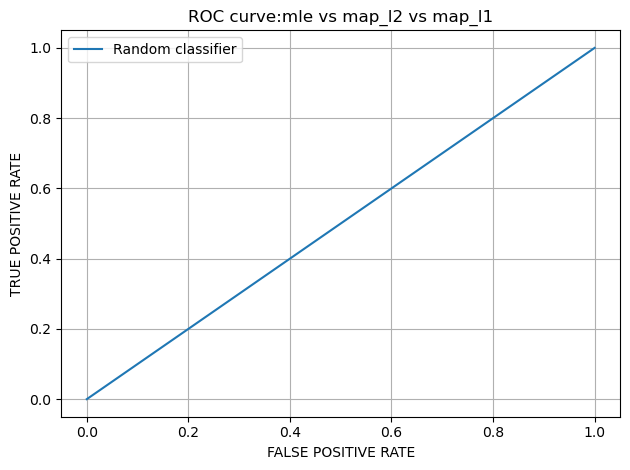

In [26]:
plt.plot(
    [0,1],
    [0,1],
    linestyle='-',
    label="Random classifier"
)

plt.xlabel("FALSE POSITIVE RATE")
plt.ylabel("TRUE POSITIVE RATE")
plt.title("ROC curve:mle vs map_l2 vs map_l1")
plt.legend()
plt.grid(True)
plt.tight_layout()